In [2]:
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

# 1. Configuration
CATEGORIES = ['alt.atheism', 'comp.graphics', 'comp.sys.mac.hardware', 'rec.autos', 'sci.space']
DATA_SIZES = [0.1, 0.2, 0.4, 0.6, 0.8, 1.0]
SEEDS = [42, 43, 44, 45, 46]

MODELS = {
    'Multinomial NB': MultinomialNB(),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Linear SVM': LinearSVC(max_iter=1000, random_state=42)
}

# 2. Load Dataset
print("Loading official dataset splits...")
data_train = fetch_20newsgroups(subset='train', categories=CATEGORIES, remove=('headers', 'footers', 'quotes'))
data_test = fetch_20newsgroups(subset='test', categories=CATEGORIES, remove=('headers', 'footers', 'quotes'))

X_train_full, y_train_full = data_train.data, data_train.target
X_test, y_test = data_test.data, data_test.target

# 3. Experimental Loop
results = []

for size in DATA_SIZES:
    for seed in SEEDS:
        # Stratified sampling
        if size == 1.0:
            X_train_sub, y_train_sub = X_train_full, y_train_full
        else:
            X_train_sub, _, y_train_sub, _ = train_test_split(
                X_train_full, y_train_full, train_size=size, stratify=y_train_full, random_state=seed
            )
        
        # TF-IDF Feature Extraction (Fitted ONLY on current training subset)
        vectorizer = TfidfVectorizer(ngram_range=(1, 2), stop_words='english')
        X_train_vec = vectorizer.fit_transform(X_train_sub)
        X_test_vec = vectorizer.transform(X_test)
        
        # Train and Evaluate Models
        for model_name, model in MODELS.items():
            model.fit(X_train_vec, y_train_sub)
            y_pred = model.predict(X_test_vec)
            
            # Metrics
            acc = accuracy_score(y_test, y_pred)
            precision, recall, f1_macro, _ = precision_recall_fscore_support(y_test, y_pred, average='macro', zero_division=0)
            _, _, f1_weighted, _ = precision_recall_fscore_support(y_test, y_pred, average='weighted', zero_division=0)
            
            results.append({
                'Model': model_name,
                'Dataset Size (%)': int(size * 100),
                'Seed': seed,
                'Accuracy': acc,
                'Precision (Macro)': precision,
                'Recall (Macro)': recall,
                'Macro-F1': f1_macro,
                'Weighted-F1': f1_weighted
            })

df_results = pd.DataFrame(results)

# 4. Statistical Analysis (Friedman Test on Macro-F1 for Linear SVM)
svm_results = df_results[df_results['Model'] == 'Linear SVM']
pivot_svm = svm_results.pivot(index='Seed', columns='Dataset Size (%)', values='Macro-F1')
stat, p_val = stats.friedmanchisquare(*[pivot_svm[col].values for col in pivot_svm.columns])

# 5. Export and Output
df_results.to_csv('experiment_results.csv', index=False)

Loading official dataset splits...


In [4]:
pip install pandas numpy scikit-learn scipy matplotlib seaborn

  Using cached numpy-1.26.4-cp312-cp312-macosx_11_0_arm64.whl.metadata (61 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 5.4 MB/s eta 0:00:0031m5.8 MB/s eta 0:00:01
Using cached numpy-1.26.4-cp312-cp312-macosx_11_0_arm64.whl (13.7 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 2.4.4
    Uninstalling numpy-2.4.4:
      Successfully uninstalled numpy-2.4.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gensim 4.3.3 requires scipy<1.14.0,>=1.7.0, but you have scipy 1.17.1 which is incompatible.
streamlit 1.37.1 requires pandas<3,>=1.3.0, but you have pandas 3.0.6 which is incompatible.
opencv-python 4.13.0.92 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


In [4]:
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

# 1. Configuration
CATEGORIES = ['alt.atheism', 'comp.graphics', 'comp.sys.mac.hardware', 'rec.autos', 'sci.space']
DATA_SIZES = [0.1, 0.2, 0.4, 0.6, 0.8, 1.0]
SEEDS = [42, 43, 44, 45, 46]

MODELS = {
    'Multinomial NB': MultinomialNB(),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Linear SVM': LinearSVC(max_iter=1000, random_state=42)
}

# 2. Load Dataset
print("Loading official dataset splits...")
data_train = fetch_20newsgroups(subset='train', categories=CATEGORIES, remove=('headers', 'footers', 'quotes'))
data_test = fetch_20newsgroups(subset='test', categories=CATEGORIES, remove=('headers', 'footers', 'quotes'))

X_train_full, y_train_full = data_train.data, data_train.target
X_test, y_test = data_test.data, data_test.target

# 3. Experimental Loop
results = []

for size in DATA_SIZES:
    for seed in SEEDS:
        # Stratified sampling
        if size == 1.0:
            X_train_sub, y_train_sub = X_train_full, y_train_full
        else:
            X_train_sub, _, y_train_sub, _ = train_test_split(
                X_train_full, y_train_full, train_size=size, stratify=y_train_full, random_state=seed
            )
        
        # TF-IDF Feature Extraction (Fitted ONLY on current training subset)
        vectorizer = TfidfVectorizer(ngram_range=(1, 2), stop_words='english')
        X_train_vec = vectorizer.fit_transform(X_train_sub)
        X_test_vec = vectorizer.transform(X_test)
        
        # Train and Evaluate Models
        for model_name, model in MODELS.items():
            model.fit(X_train_vec, y_train_sub)
            y_pred = model.predict(X_test_vec)
            
            # Metrics
            acc = accuracy_score(y_test, y_pred)
            precision, recall, f1_macro, _ = precision_recall_fscore_support(y_test, y_pred, average='macro', zero_division=0)
            _, _, f1_weighted, _ = precision_recall_fscore_support(y_test, y_pred, average='weighted', zero_division=0)
            
            results.append({
                'Model': model_name,
                'Dataset Size (%)': int(size * 100),
                'Seed': seed,
                'Accuracy': acc,
                'Precision (Macro)': precision,
                'Recall (Macro)': recall,
                'Macro-F1': f1_macro,
                'Weighted-F1': f1_weighted
            })

df_results = pd.DataFrame(results)

# 4. Statistical Analysis (Friedman Test on Macro-F1 for Linear SVM)
svm_results = df_results[df_results['Model'] == 'Linear SVM']
pivot_svm = svm_results.pivot(index='Seed', columns='Dataset Size (%)', values='Macro-F1')
stat, p_val = stats.friedmanchisquare(*[pivot_svm[col].values for col in pivot_svm.columns])

# 5. Export and Output
df_results.to_csv('experiment_results.csv', index=False)

Loading official dataset splits...


In [6]:
# Print the statistical analysis results
print(f"Friedman Test - Statistic: {stat:.4f}, p-value: {p_val:.4f}")

# Display the dataframe in the notebook
display(df_results)

Friedman Test - Statistic: 24.3143, p-value: 0.0002


,Model,Dataset Size (%),Seed,Accuracy,Precision (Macro),Recall (Macro),Macro-F1,Weighted-F1
0,Multinomial NB,10,42,0.734997,0.765451,0.728211,0.732415,0.733550
1,Logistic Regression,10,42,0.745619,0.776489,0.739399,0.745239,0.745968
2,Linear SVM,10,42,0.753054,0.762458,0.752176,0.753988,0.753201
3,Multinomial NB,10,43,0.750398,0.778914,0.739664,0.739425,0.743891
4,Logistic Regression,10,43,0.754647,0.782645,0.746129,0.749957,0.752758
...,...,...,...,...,...,...,...,...
85,Logistic Regression,100,45,0.835900,0.844045,0.832660,0.835383,0.836123
86,Linear SVM,100,45,0.845990,0.850116,0.843951,0.845296,0.846110
87,Multinomial NB,100,46,0.839618,0.853208,0.834349,0.838341,0.839388
88,Logistic Regression,100,46,0.835900,0.844045,0.832660,0.835383,0.836123


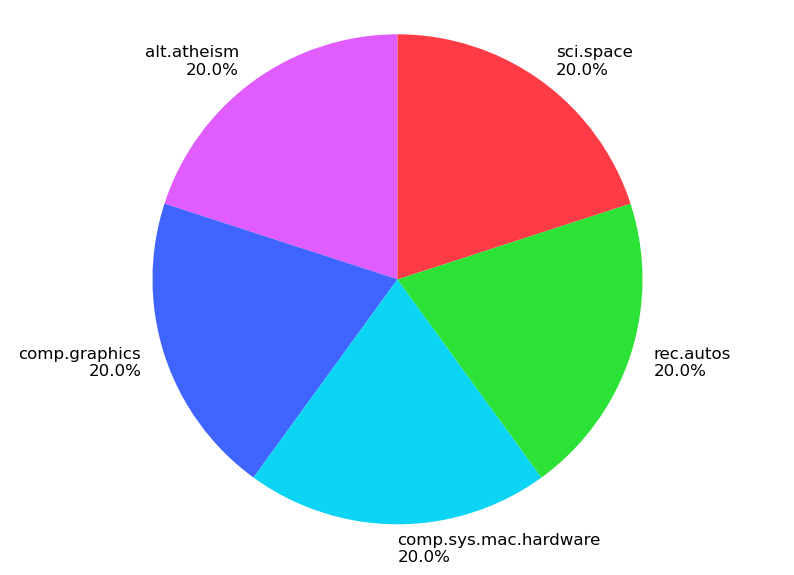

In [12]:
import matplotlib.pyplot as plt

# Categories from your 20 Newsgroups subset
labels = [
    'alt.atheism\n20.0%',
    'comp.graphics\n20.0%',
    'comp.sys.mac.hardware\n20.0%',
    'rec.autos\n20.0%',
    'sci.space\n20.0%'
]

# Equal distribution based on the "nearly evenly" partitioned dataset
sizes = [20.0, 20.0, 20.0, 20.0, 20.0]

# Bright hex color codes matching the visual style of the reference chart
colors = [
    '#e05cff',  # light purple/magenta
    '#4064ff',  # blue
    '#0bd4f4',  # cyan
    '#2de236',  # green
    '#ff3b45'   # red
]

# Set up the figure
plt.figure(figsize=(10, 7))

# Create the pie chart with labels outside
plt.pie(sizes, 
        labels=labels, 
        colors=colors, 
        startangle=90, 
        labeldistance=1.1, 
        textprops={'fontsize': 12})

# Ensure the pie is drawn as a perfect circle
plt.axis('equal')

# Display the chart
plt.show()

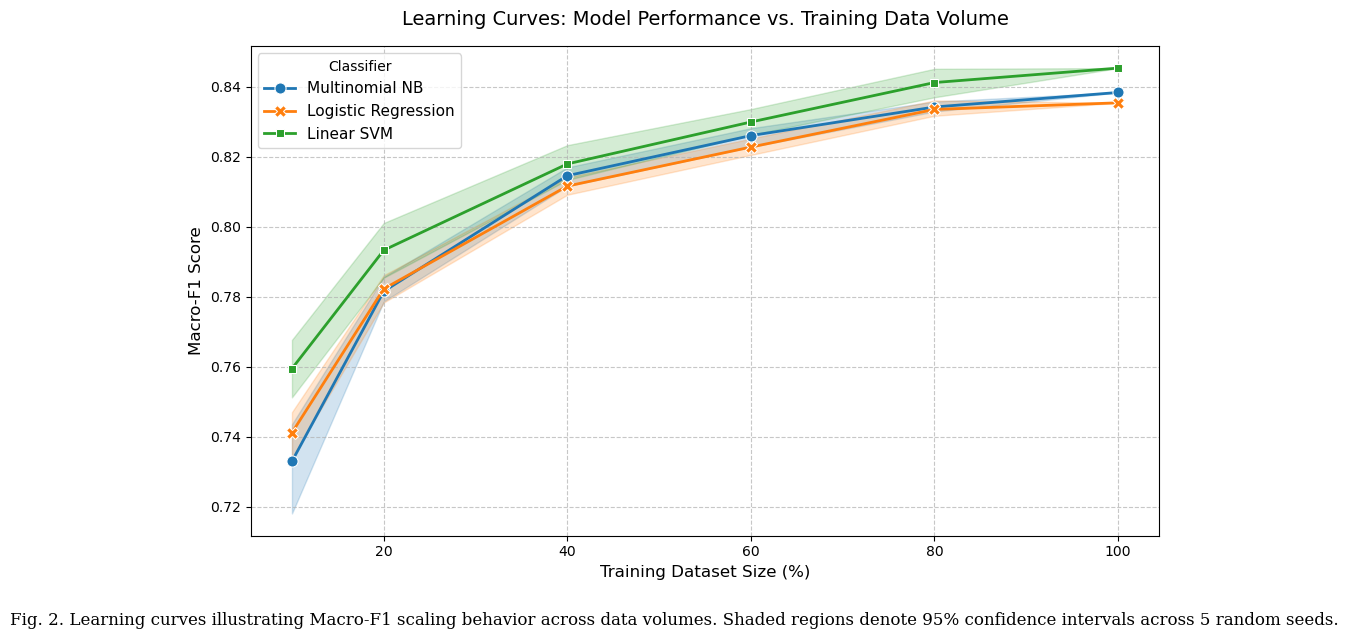

In [14]:
plt.figure(figsize=(10, 6))
# Seaborn automatically aggregates the seeds and plots the mean with a 95% confidence interval band
sns.lineplot(
    data=df_results, 
    x='Dataset Size (%)', 
    y='Macro-F1', 
    hue='Model', 
    style='Model', 
    markers=True, 
    dashes=False,
    linewidth=2,
    markersize=8
)

plt.title('Learning Curves: Model Performance vs. Training Data Volume', fontsize=14, pad=15)
plt.xlabel('Training Dataset Size (%)', fontsize=12)
plt.ylabel('Macro-F1 Score', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(title='Classifier', fontsize=11)
plt.tight_layout()

# Caption for the paper
plt.figtext(0.5, -0.05, 
            "Fig. 2. Learning curves illustrating Macro-F1 scaling behavior across data volumes. Shaded regions denote 95% confidence intervals across 5 random seeds.", 
            ha="center", fontsize=12, fontfamily='serif')
plt.show()

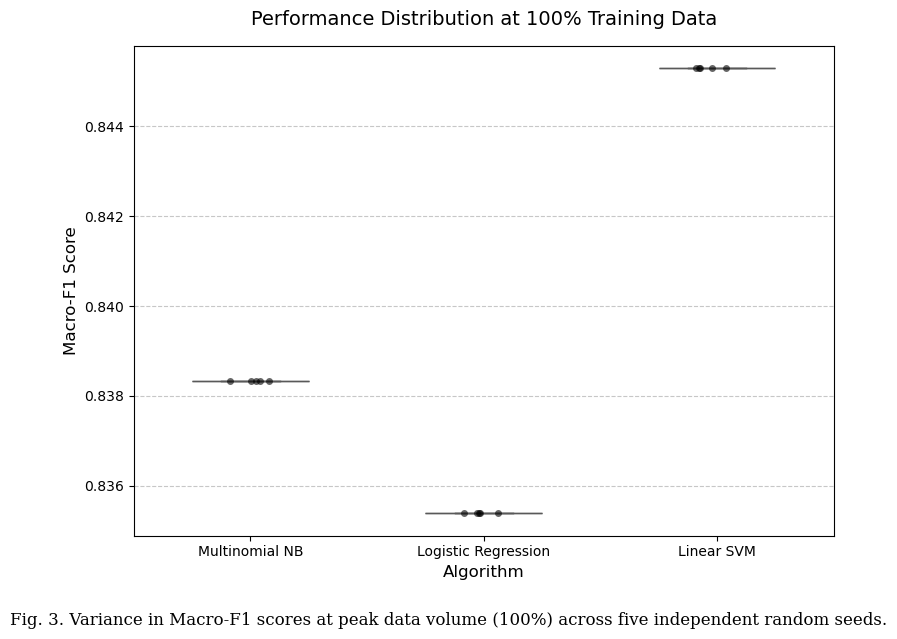

In [16]:
plt.figure(figsize=(8, 6))
# Filter data to only show the final 100% dataset size
df_100 = df_results[df_results['Dataset Size (%)'] == 100]

sns.boxplot(
    data=df_100, 
    x='Model', 
    y='Macro-F1', 
    palette='Set2',
    width=0.5
)
# Add individual data points on top of the boxes to show the exact seed results
sns.stripplot(data=df_100, x='Model', y='Macro-F1', color='black', alpha=0.6, jitter=True)

plt.title('Performance Distribution at 100% Training Data', fontsize=14, pad=15)
plt.xlabel('Algorithm', fontsize=12)
plt.ylabel('Macro-F1 Score', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

# Caption for the paper
plt.figtext(0.5, -0.05, 
            "Fig. 3. Variance in Macro-F1 scores at peak data volume (100%) across five independent random seeds.", 
            ha="center", fontsize=12, fontfamily='serif')
plt.show()

In [18]:
# Calculate mean and standard deviation for the 100% dataset size across all 5 seeds
summary_table = df_results[df_results['Dataset Size (%)'] == 100].groupby('Model').agg(
    Accuracy_Mean=('Accuracy', 'mean'),
    Accuracy_Std=('Accuracy', 'std'),
    MacroF1_Mean=('Macro-F1', 'mean'),
    MacroF1_Std=('Macro-F1', 'std')
).reset_index()

# Format the results into standard academic "Mean ± Std" string format
summary_table['Accuracy (Mean ± SD)'] = summary_table.apply(lambda x: f"{x['Accuracy_Mean']:.4f} ± {x['Accuracy_Std']:.4f}", axis=1)
summary_table['Macro-F1 (Mean ± SD)'] = summary_table.apply(lambda x: f"{x['MacroF1_Mean']:.4f} ± {x['MacroF1_Std']:.4f}", axis=1)

# Keep only the formatted columns
final_table = summary_table[['Model', 'Accuracy (Mean ± SD)', 'Macro-F1 (Mean ± SD)']]

print("Table 1: Final Classification Performance at 100% Data Volume")
display(final_table)


Table 1: Final Classification Performance at 100% Data Volume


,Model,Accuracy (Mean ± SD),Macro-F1 (Mean ± SD)
0,Linear SVM,0.8460 ± 0.0000,0.8453 ± 0.0000
1,Logistic Regression,0.8359 ± 0.0000,0.8354 ± 0.0000
2,Multinomial NB,0.8396 ± 0.0000,0.8383 ± 0.0000


In [20]:
# Group by both Dataset Size and Model to get mean and standard deviation for Macro-F1
agg_df = df_results.groupby(['Dataset Size (%)', 'Model'])['Macro-F1'].agg(['mean', 'std']).reset_index()

# Format the results into the standard academic "Mean ± Std" string format
agg_df['Mean ± SD'] = agg_df.apply(lambda x: f"{x['mean']:.4f} ± {x['std']:.4f}", axis=1)

# Pivot the table to perfectly match the layout of Table 4 in your Word document
pivot_table = agg_df.pivot(index='Dataset Size (%)', columns='Model', values='Mean ± SD')

# Reorder columns to match your exact document structure
pivot_table = pivot_table[['Multinomial NB', 'Logistic Regression', 'Linear SVM']]

print("Data for Table 4: Mean Macro-F1 ± Standard Deviation")
display(pivot_table)


Data for Table 4: Mean Macro-F1 ± Standard Deviation


Model,Multinomial NB,Logistic Regression,Linear SVM
Dataset Size (%),,,
10,0.7330 ± 0.0170,0.7412 ± 0.0082,0.7595 ± 0.0108
20,0.7816 ± 0.0046,0.7823 ± 0.0051,0.7933 ± 0.0104
40,0.8146 ± 0.0038,0.8116 ± 0.0032,0.8179 ± 0.0063
60,0.8260 ± 0.0036,0.8228 ± 0.0031,0.8299 ± 0.0052
80,0.8342 ± 0.0018,0.8335 ± 0.0028,0.8412 ± 0.0052
100,0.8383 ± 0.0000,0.8354 ± 0.0000,0.8453 ± 0.0000


In [22]:
# Filter the results to only include Seed 42
table5_data = df_results[df_results['Seed'] == 42].copy()

# Select the specific columns needed for your Word document
columns_to_keep = [
    'Dataset Size (%)', 'Model', 'Accuracy', 
    'Precision (Macro)', 'Recall (Macro)', 
    'Macro-F1', 'Weighted-F1'
]
table5_filtered = table5_data[columns_to_keep]

# Round the numerical metrics to 4 decimal places for a clean presentation
metrics_cols = ['Accuracy', 'Precision (Macro)', 'Recall (Macro)', 'Macro-F1', 'Weighted-F1']
table5_filtered[metrics_cols] = table5_filtered[metrics_cols].round(4)

print("Data for Table 5: Detailed Results (Seed = 42)")
display(table5_filtered)

Data for Table 5: Detailed Results (Seed = 42)


,Dataset Size (%),Model,Accuracy,Precision (Macro),Recall (Macro),Macro-F1,Weighted-F1
0,10,Multinomial NB,0.7350,0.7655,0.7282,0.7324,0.7336
1,10,Logistic Regression,0.7456,0.7765,0.7394,0.7452,0.7460
2,10,Linear SVM,0.7531,0.7625,0.7522,0.7540,0.7532
15,20,Multinomial NB,0.7807,0.8059,0.7739,0.7786,0.7801
16,20,Logistic Regression,0.7801,0.7979,0.7750,0.7796,0.7803
17,20,Linear SVM,0.7828,0.7870,0.7811,0.7829,0.7830
30,40,Multinomial NB,0.8104,0.8274,0.8045,0.8086,0.8097
31,40,Logistic Regression,0.8099,0.8217,0.8063,0.8097,0.8101
32,40,Linear SVM,0.8104,0.8145,0.8088,0.8098,0.8104
45,60,Multinomial NB,0.8295,0.8444,0.8239,0.8280,0.8291


In [24]:
import pandas as pd

# Calculate the exact counts for each category using your existing variables
train_counts = pd.Series(y_train_full).value_counts().sort_index()
test_counts = pd.Series(y_test).value_counts().sort_index()

# Create a DataFrame tailored for Table 3
table3 = pd.DataFrame({
    'Category': CATEGORIES,
    'Training Samples': train_counts.values,
    'Testing Samples': test_counts.values
})

# Add the Total Samples column
table3['Total Samples'] = table3['Training Samples'] + table3['Testing Samples']

# Calculate the grand totals for the bottom row
total_row = pd.DataFrame({
    'Category': ['Total'],
    'Training Samples': [table3['Training Samples'].sum()],
    'Testing Samples': [table3['Testing Samples'].sum()],
    'Total Samples': [table3['Total Samples'].sum()]
})

# Combine and display
table3_final = pd.concat([table3, total_row], ignore_index=True)
print("Data for Table 3: Dataset Characteristics")
display(table3_final)

Data for Table 3: Dataset Characteristics


,Category,Training Samples,Testing Samples,Total Samples
0,alt.atheism,480,319,799
1,comp.graphics,584,389,973
2,comp.sys.mac.hardware,578,385,963
3,rec.autos,594,396,990
4,sci.space,593,394,987
5,Total,2829,1883,4712


In [26]:
import scipy.stats as stats

# Function to calculate Friedman test for a given model
def run_friedman(model_name):
    model_data = df_results[df_results['Model'] == model_name]
    # Pivot the data so columns are data sizes and rows are seeds
    pivot_data = model_data.pivot(index='Seed', columns='Dataset Size (%)', values='Macro-F1')
    # Run Friedman test across the different data sizes
    stat, p_val = stats.friedmanchisquare(*[pivot_data[col].values for col in pivot_data.columns])
    return stat, p_val

# Calculate and print for all models
print("Data for Table 6: Statistical Significance Results")
for model in ['Multinomial NB', 'Logistic Regression', 'Linear SVM']:
    stat, p = run_friedman(model)
    sig = "Significant" if p < 0.05 else "Not Significant"
    print(f"{model} | Friedman Test | {stat:.4f} | {p:.4f} | {sig}")

Data for Table 6: Statistical Significance Results
Multinomial NB | Friedman Test | 25.0000 | 0.0001 | Significant
Logistic Regression | Friedman Test | 24.5429 | 0.0002 | Significant
Linear SVM | Friedman Test | 24.3143 | 0.0002 | Significant


In [28]:
from scipy.stats import shapiro, levene

# 1. Shapiro-Wilk test for normality on all Macro-F1 scores
stat_sw, p_sw = shapiro(df_results['Macro-F1'])
print(f"Shapiro-Wilk p-value: {p_sw:.4e}")

# 2. Levene's test for homoscedasticity (equal variance) across dataset size groups
sizes = df_results['Dataset Size (%)'].unique()
groups = [df_results[df_results['Dataset Size (%)'] == size]['Macro-F1'].values for size in sizes]
stat_lev, p_lev = levene(*groups)
print(f"Levene's test p-value: {p_lev:.4e}")

Shapiro-Wilk p-value: 1.5038e-07
Levene's test p-value: 6.6374e-03


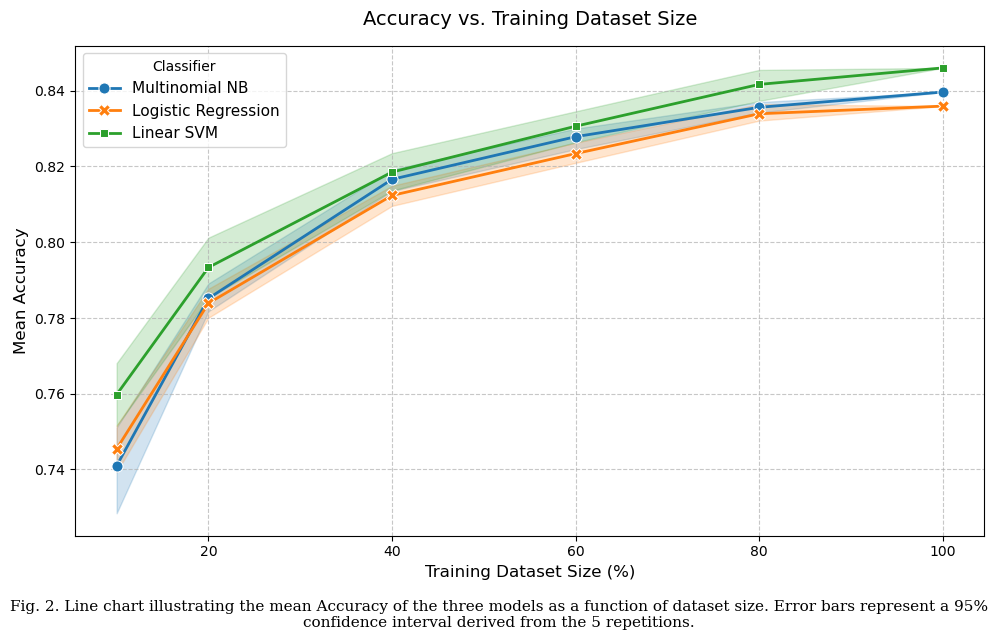

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
# Seaborn automatically calculates the 95% confidence intervals across your 5 seeds
sns.lineplot(
    data=df_results, 
    x='Dataset Size (%)', 
    y='Accuracy', 
    hue='Model', 
    style='Model', 
    markers=True, 
    dashes=False,
    linewidth=2,
    markersize=8
)

plt.title('Accuracy vs. Training Dataset Size', fontsize=14, pad=15)
plt.xlabel('Training Dataset Size (%)', fontsize=12)
plt.ylabel('Mean Accuracy', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(title='Classifier', fontsize=11)
plt.tight_layout()

# This caption exactly matches your Word document requirements
plt.figtext(0.5, -0.05, 
            "Fig. 2. Line chart illustrating the mean Accuracy of the three models as a function of dataset size. Error bars represent a 95% confidence interval derived from the 5 repetitions.", 
            ha="center", fontsize=11, fontfamily='serif', wrap=True)
plt.show()

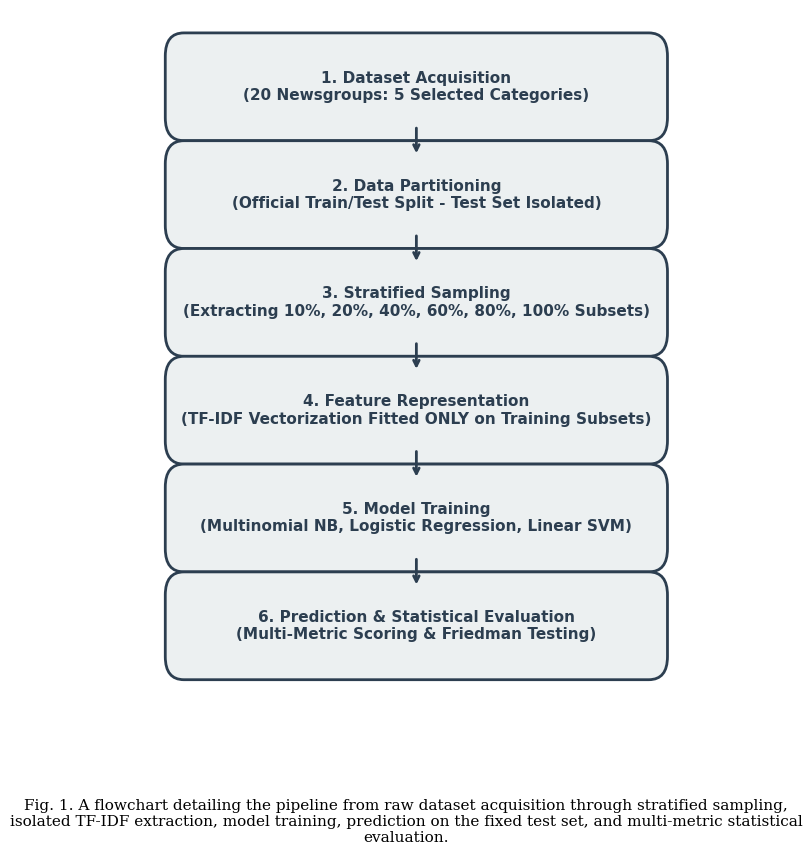

In [32]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

fig, ax = plt.subplots(figsize=(8, 10))
ax.axis('off')

# The 6 core steps of your methodology
steps = [
    "1. Dataset Acquisition\n(20 Newsgroups: 5 Selected Categories)",
    "2. Data Partitioning\n(Official Train/Test Split - Test Set Isolated)",
    "3. Stratified Sampling\n(Extracting 10%, 20%, 40%, 60%, 80%, 100% Subsets)",
    "4. Feature Representation\n(TF-IDF Vectorization Fitted ONLY on Training Subsets)",
    "5. Model Training\n(Multinomial NB, Logistic Regression, Linear SVM)",
    "6. Prediction & Statistical Evaluation\n(Multi-Metric Scoring & Friedman Testing)"
]

box_width = 0.75
box_height = 0.08
x_center = 0.5
y_start = 0.9
y_gap = 0.14

for i, step in enumerate(steps):
    y = y_start - i * y_gap
    
    # Draw the flowchart box
    box = patches.FancyBboxPatch(
        (x_center - box_width/2, y - box_height/2),
        box_width, box_height,
        boxstyle="round,pad=0.03",
        edgecolor='#2c3e50',
        facecolor='#ecf0f1',
        lw=2
    )
    ax.add_patch(box)
    
    # Insert the text inside the box
    ax.text(x_center, y, step, ha='center', va='center', 
            fontsize=11, fontweight='bold', color='#2c3e50')
    
    # Draw a downward arrow to the next box
    if i < len(steps) - 1:
        ax.annotate('', 
                    xy=(x_center, y - box_height/2 - (y_gap - box_height) + 0.01), 
                    xytext=(x_center, y - box_height/2 - 0.01),
                    arrowprops=dict(arrowstyle="->", color='#2c3e50', lw=2))

# Add the specific caption required by your paper
plt.figtext(0.5, 0.05, 
            "Fig. 1. A flowchart detailing the pipeline from raw dataset acquisition through stratified sampling,\nisolated TF-IDF extraction, model training, prediction on the fixed test set, and multi-metric statistical evaluation.", 
            ha="center", fontsize=11, fontfamily='serif', wrap=True)

plt.show()

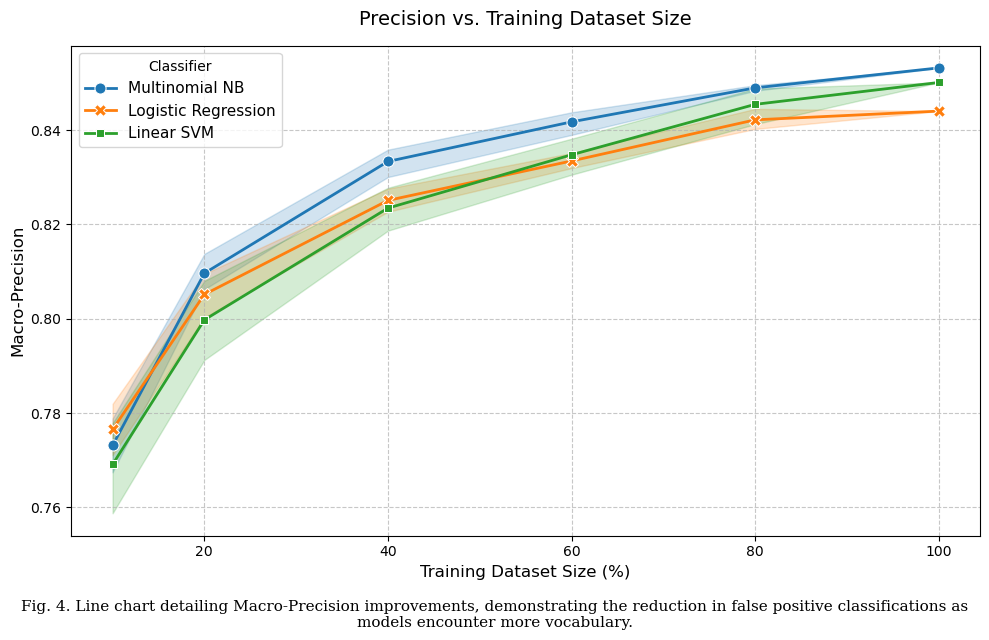

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.lineplot(data=df_results, x='Dataset Size (%)', y='Precision (Macro)', hue='Model', style='Model', markers=True, dashes=False, linewidth=2, markersize=8)

plt.title('Precision vs. Training Dataset Size', fontsize=14, pad=15)
plt.xlabel('Training Dataset Size (%)', fontsize=12)
plt.ylabel('Macro-Precision', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(title='Classifier', fontsize=11)
plt.tight_layout()

plt.figtext(0.5, -0.05, "Fig. 4. Line chart detailing Macro-Precision improvements, demonstrating the reduction in false positive classifications as models encounter more vocabulary.", ha="center", fontsize=11, fontfamily='serif', wrap=True)
plt.show()

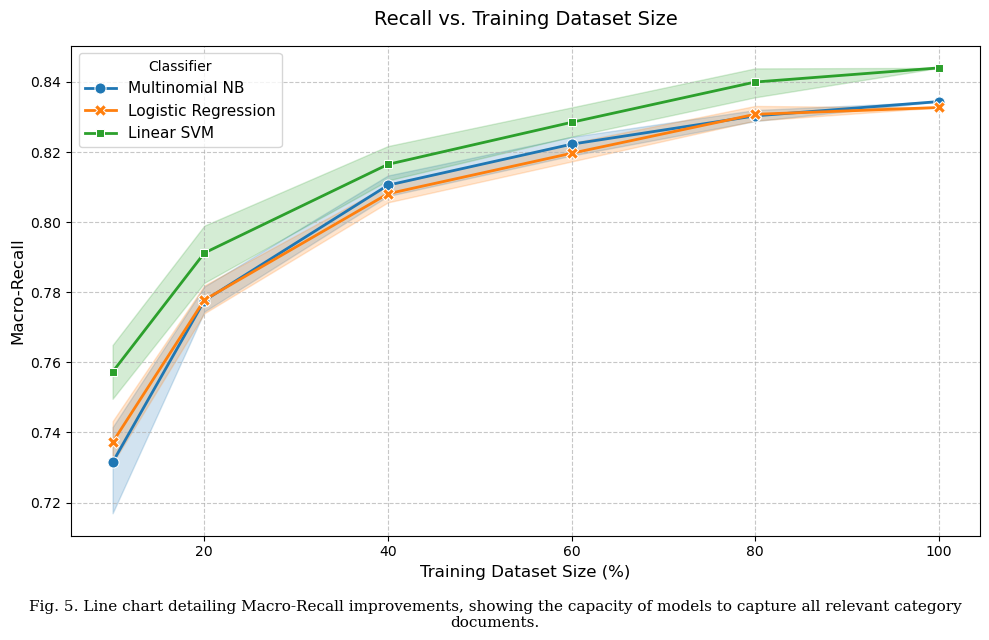

In [36]:
plt.figure(figsize=(10, 6))
sns.lineplot(data=df_results, x='Dataset Size (%)', y='Recall (Macro)', hue='Model', style='Model', markers=True, dashes=False, linewidth=2, markersize=8)

plt.title('Recall vs. Training Dataset Size', fontsize=14, pad=15)
plt.xlabel('Training Dataset Size (%)', fontsize=12)
plt.ylabel('Macro-Recall', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(title='Classifier', fontsize=11)
plt.tight_layout()

plt.figtext(0.5, -0.05, "Fig. 5. Line chart detailing Macro-Recall improvements, showing the capacity of models to capture all relevant category documents.", ha="center", fontsize=11, fontfamily='serif', wrap=True)
plt.show()

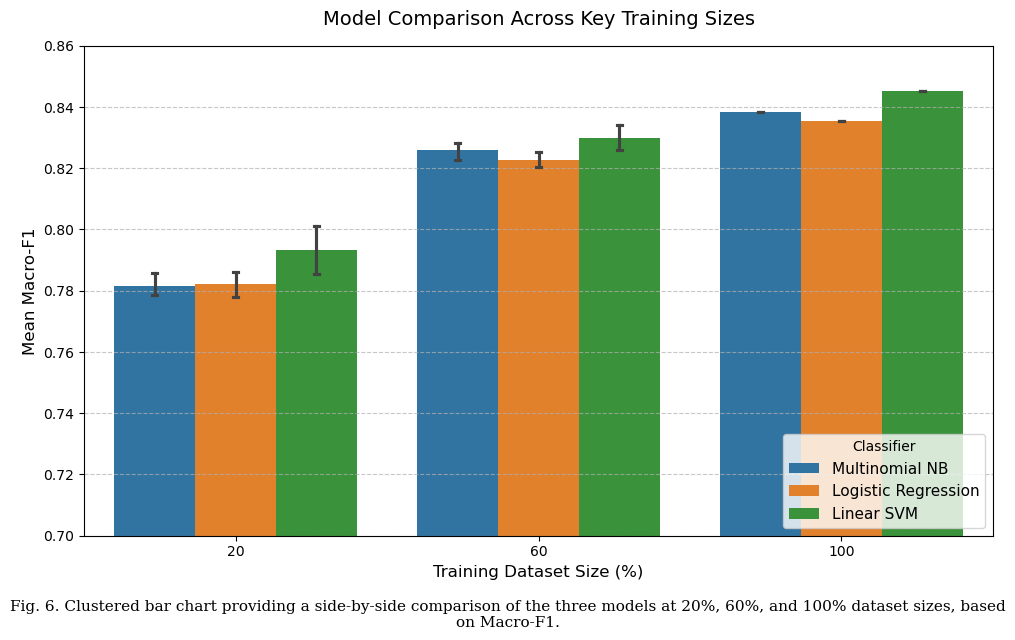

In [38]:
plt.figure(figsize=(10, 6))
# Filter data for only the specific sizes requested
df_filtered = df_results[df_results['Dataset Size (%)'].isin([20, 60, 100])]

sns.barplot(data=df_filtered, x='Dataset Size (%)', y='Macro-F1', hue='Model', errorbar=('ci', 95), capsize=0.05)

plt.title('Model Comparison Across Key Training Sizes', fontsize=14, pad=15)
plt.xlabel('Training Dataset Size (%)', fontsize=12)
plt.ylabel('Mean Macro-F1', fontsize=12)
# Set y-axis limits to better visualize the differences at the top end
plt.ylim(0.70, 0.86) 
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(title='Classifier', fontsize=11, loc='lower right')
plt.tight_layout()

plt.figtext(0.5, -0.05, "Fig. 6. Clustered bar chart providing a side-by-side comparison of the three models at 20%, 60%, and 100% dataset sizes, based on Macro-F1.", ha="center", fontsize=11, fontfamily='serif', wrap=True)
plt.show()

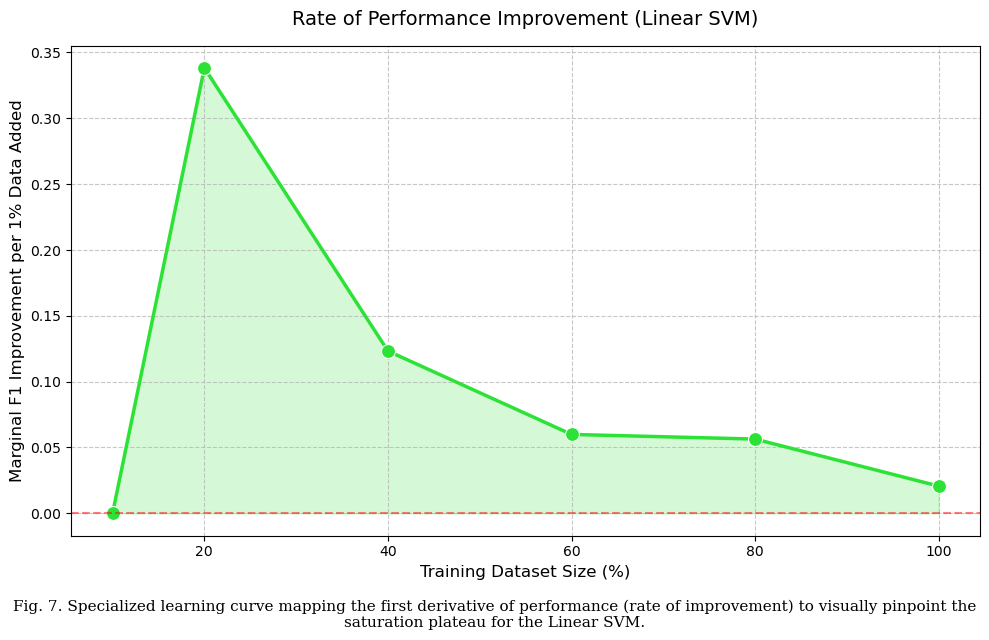

In [40]:
plt.figure(figsize=(10, 6))

# Isolate Linear SVM and calculate the mean for each size
svm_means = df_results[df_results['Model'] == 'Linear SVM'].groupby('Dataset Size (%)')['Macro-F1'].mean().sort_index()

# Calculate the discrete difference (rate of improvement) between steps
# We divide by the step size (e.g., 20 - 10 = 10) to normalize the rate
step_sizes = svm_means.index.to_series().diff().fillna(10) # 10% is the initial step
improvement_rate = (svm_means.diff().fillna(0) / step_sizes) * 100 

# Plot the rate of improvement
sns.lineplot(x=improvement_rate.index, y=improvement_rate.values, marker='o', color='#2de236', linewidth=2.5, markersize=10)

plt.axhline(0, color='red', linestyle='--', alpha=0.5) # Baseline showing zero improvement
plt.fill_between(improvement_rate.index, improvement_rate.values, alpha=0.2, color='#2de236')

plt.title('Rate of Performance Improvement (Linear SVM)', fontsize=14, pad=15)
plt.xlabel('Training Dataset Size (%)', fontsize=12)
plt.ylabel('Marginal F1 Improvement per 1% Data Added', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()

plt.figtext(0.5, -0.05, "Fig. 7. Specialized learning curve mapping the first derivative of performance (rate of improvement) to visually pinpoint the saturation plateau for the Linear SVM.", ha="center", fontsize=11, fontfamily='serif', wrap=True)
plt.show()